In [1]:
import sys
print(sys.executable)

C:\Users\Usuario\anaconda3\envs\stockifai\python.exe


In [2]:
import pandas as pd

ruta = "../data/raw/Import-Movimientos.xlsx"
mov = pd.read_excel(ruta)
mov.shape


(70193, 8)

In [3]:
mov.head()

,KardexId,Repuesto,Descripcion,Fecha,Cantidad,Tipo,Documento,Deposito
0,4061504,16546ET00A,FILTRO DE AIRE,2025-07-24,1,E,VA-X-0001-00030325,CENTRAL
1,4061505,1520865F0E,VALVULA FILTRO ACEITE H4M KD,2025-07-24,1,E,VA-X-0001-00030325,CENTRAL
2,4061506,NIS7000008,LIMPIA PARABRISA X 1 LTS,2025-07-24,1,E,VA-X-0001-00030325,CENTRAL
3,4061507,NIS7123042,M-SUPER 2000 X3 10W40 24X1L,2025-07-24,4,E,VA-X-0001-00030325,D3
4,4061508,165463AW0J,FILTRO DE AIRE,2025-07-24,1,E,VA-X-0001-00030326,CENTRAL


In [4]:
mov.dtypes

KardexId                int64
Repuesto                  str
Descripcion               str
Fecha          datetime64[us]
Cantidad                int64
Tipo                      str
Documento                 str
Deposito                  str
dtype: object

In [5]:
mov.isna().sum()

KardexId       0
Repuesto       0
Descripcion    0
Fecha          0
Cantidad       0
Tipo           0
Documento      0
Deposito       0
dtype: int64

In [6]:
mov['Tipo'].value_counts()

Tipo
E    70193
Name: count, dtype: int64

In [7]:
mov['Deposito'].value_counts()

Deposito
CENTRAL      61975
D3            5999
PICKING       1976
PAJARERA       237
GARANTIAS        6
Name: count, dtype: int64

In [8]:
mov['Documento']

0        VA-X-0001-00030325
1        VA-X-0001-00030325
2        VA-X-0001-00030325
3        VA-X-0001-00030325
4        VA-X-0001-00030326
                ...        
70188    VA-X-0001-00015882
70189    VA-X-0001-00015882
70190    VA-X-0001-00015882
70191    VA-X-0001-00015882
70192    VA-X-0001-00015882
Name: Documento, Length: 70193, dtype: str

In [9]:
mov["prefijo"] = mov["Documento"].str.split("-").str[0]
mov["prefijo"].value_counts()

prefijo
VA    48298
FC    21895
Name: count, dtype: int64

In [10]:
mov.head()

,KardexId,Repuesto,Descripcion,Fecha,Cantidad,Tipo,Documento,Deposito,prefijo
0,4061504,16546ET00A,FILTRO DE AIRE,2025-07-24,1,E,VA-X-0001-00030325,CENTRAL,VA
1,4061505,1520865F0E,VALVULA FILTRO ACEITE H4M KD,2025-07-24,1,E,VA-X-0001-00030325,CENTRAL,VA
2,4061506,NIS7000008,LIMPIA PARABRISA X 1 LTS,2025-07-24,1,E,VA-X-0001-00030325,CENTRAL,VA
3,4061507,NIS7123042,M-SUPER 2000 X3 10W40 24X1L,2025-07-24,4,E,VA-X-0001-00030325,D3,VA
4,4061508,165463AW0J,FILTRO DE AIRE,2025-07-24,1,E,VA-X-0001-00030326,CENTRAL,VA


In [11]:
pd.crosstab(mov['prefijo'], mov['Deposito'])

Deposito,CENTRAL,D3,GARANTIAS,PAJARERA,PICKING
prefijo,,,,,
FC,19902,685,1,83,1224
VA,42073,5314,5,154,752


In [12]:
mov.groupby("Deposito")["Fecha"].agg(["min","max"])

,min,max
Deposito,,
CENTRAL,2020-08-12,2025-07-24
D3,2020-08-12,2025-07-24
GARANTIAS,2021-02-01,2024-10-23
PAJARERA,2024-06-28,2025-07-21
PICKING,2020-08-12,2025-07-23


In [13]:
mov["semana"] = mov['Fecha'].dt.to_period('W').dt.start_time

In [14]:
mov[["Repuesto", "Fecha", "semana"]].head(10)

,Repuesto,Fecha,semana
0,16546ET00A,2025-07-24,2025-07-21
1,1520865F0E,2025-07-24,2025-07-21
2,NIS7000008,2025-07-24,2025-07-21
3,NIS7123042,2025-07-24,2025-07-21
4,165463AW0J,2025-07-24,2025-07-21
5,1520865F0E,2025-07-24,2025-07-21
6,NIS7000008,2025-07-24,2025-07-21
7,NIS7123042,2025-07-24,2025-07-21
8,165463AW0J,2025-07-24,2025-07-21
9,1520865F0E,2025-07-24,2025-07-21


In [15]:
semanal = mov.groupby(['Repuesto','semana'], as_index=False)['Cantidad'].sum()

In [16]:
semanal.shape

(28116, 3)

In [31]:
print(semanal)

         Repuesto     semana  Cantidad
0      01223A0111 2024-12-09         2
1      01223A0111 2024-12-16         6
2      01223A0111 2024-12-23         4
3      01223A0111 2024-12-30         2
4      01223A0111 2025-01-13         6
...           ...        ...       ...
28111  T99W64KH00 2024-01-22         1
28112  T99W64KH00 2024-04-22         2
28113  T99W64KH00 2024-06-10         1
28114  T99W64KH00 2024-06-24         1
28115  T99W64KH00 2024-08-12         1

[28116 rows x 3 columns]


In [17]:
por_repuesto = semanal.groupby('Repuesto')['semana'].count()

In [18]:
por_repuesto.sort_values(ascending=False).head(10)


Repuesto
16546ED00J    259
NIS7000008    259
1520865F0E    259
165463AW0J    259
165465RA0A    258
LAMPARAPOS    258
NIS0000166    257
NIS7122058    251
27891EL00B    238
272773HU0B    235
Name: semana, dtype: int64

In [19]:
por_repuesto.describe()

count    3901.000000
mean        7.207383
std        21.909787
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max       259.000000
Name: semana, dtype: float64

In [20]:
for minimo in [2,5,10,26,52]:
    cuantos = (por_repuesto>=minimo).sum()
    print(f"Venden en al menos {minimo} semanas: {cuantos} repuestos ")

Venden en al menos 2 semanas: 2084 repuestos 
Venden en al menos 5 semanas: 904 repuestos 
Venden en al menos 10 semanas: 494 repuestos 
Venden en al menos 26 semanas: 225 repuestos 
Venden en al menos 52 semanas: 99 repuestos 


In [21]:
unidades = semanal.groupby('Repuesto')['Cantidad'].sum()

In [22]:
total_unidades = unidades.sum()

In [23]:
total_repuestos = len(por_repuesto)

In [24]:
filas = []

In [25]:
for minimo in [1,2,5,10,26,52]:
    pasa = por_repuesto >= minimo
    filas.append({
        "minimo_semanas" : minimo,
        "repuestos" : pasa.sum(),
        "pct_repuestos" : round(pasa.sum() / total_repuestos * 100,1),
        "pct_unidades" : round(unidades[pasa].sum() / total_unidades * 100,1)
    })

In [26]:
tabla_cortes = pd.DataFrame(filas)
tabla_cortes

,minimo_semanas,repuestos,pct_repuestos,pct_unidades
0,1,3901,100.0,100.0
1,2,2084,53.4,97.9
2,5,904,23.2,94.2
3,10,494,12.7,90.1
4,26,225,5.8,85.5
5,52,99,2.5,79.2


### Decisión: universo de repuestos
- Entran al modelo los repuestos con al menos 10 semanas con venta:
  494 repuestos (13% del catálogo), 90% de las unidades vendidas.
- Se evaluará el error por separado para los repuestos con 10-25 semanas
  y con 26 o más. Si el modelo no le gana a la regla simple en el grupo 10-25,
  el corte sube a 26 (225 repuestos, 86% de las unidades).
- El resto de los repuestos recibe una regla simple (baseline).

In [28]:
import matplotlib.pyplot as plt

In [29]:
filtro = semanal[semanal["Repuesto"] == "16546ED00J"]
filtro.head()

,Repuesto,semana,Cantidad
5366,16546ED00J,2020-08-10,4
5367,16546ED00J,2020-08-17,3
5368,16546ED00J,2020-08-24,4
5369,16546ED00J,2020-08-31,6
5370,16546ED00J,2020-09-07,8


<Axes: title={'center': 'Filtro de aire 16546ED00J'}, xlabel='semana'>

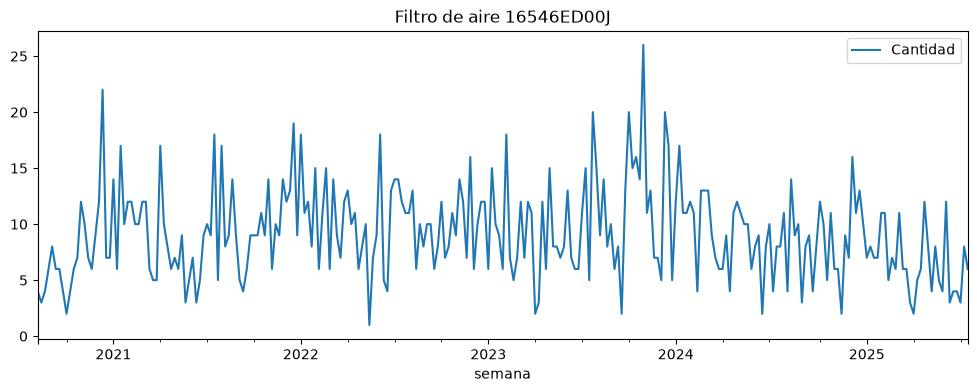

In [30]:
filtro.plot(x="semana", y="Cantidad", figsize=(12, 4), title="Filtro de aire 16546ED00J")

In [32]:
por_repuesto[por_repuesto == 12].head()

Repuesto
11062ET00A    12
117205152R    12
122791HC0A    12
1520865F1B    12
214685JL0A    12
Name: semana, dtype: int64

<Axes: title={'center': 'Repuesto intermitente'}, xlabel='semana'>

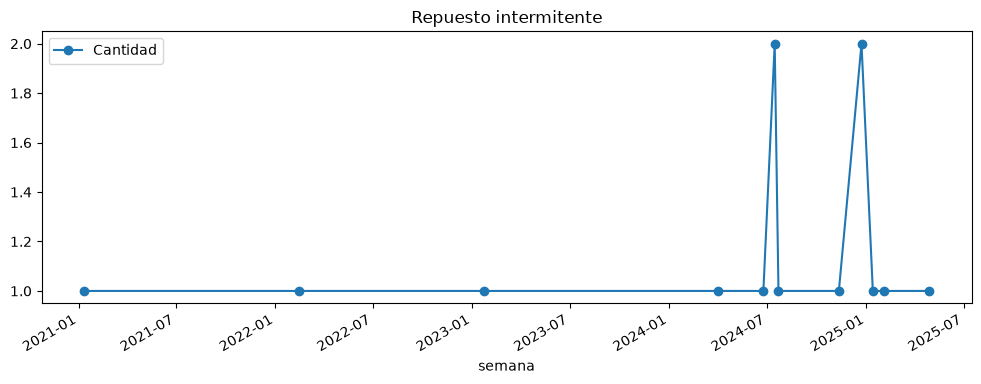

In [33]:
inter = semanal[semanal["Repuesto"] == "11062ET00A"]
inter.plot(x="semana", y="Cantidad", figsize=(12, 4), marker="o", title="Repuesto intermitente")

In [34]:
inter

,Repuesto,semana,Cantidad
216,11062ET00A,2021-01-11,1
217,11062ET00A,2022-02-14,1
218,11062ET00A,2023-01-23,1
219,11062ET00A,2024-04-01,1
220,11062ET00A,2024-06-24,1
221,11062ET00A,2024-07-15,2
222,11062ET00A,2024-07-22,1
223,11062ET00A,2024-11-11,1
224,11062ET00A,2024-12-23,2
225,11062ET00A,2025-01-13,1


<Axes: title={'center': 'Repuesto intermitente (con ceros)'}, xlabel='semana'>

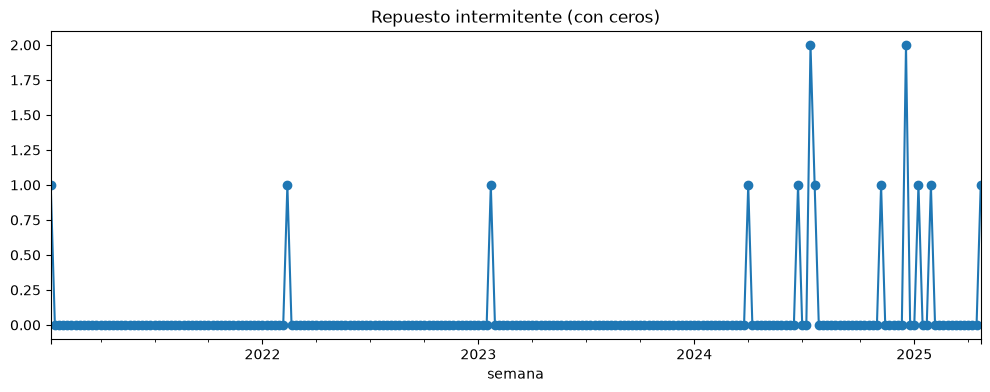

In [35]:
inter_completo = (
    inter.set_index("semana")["Cantidad"]
         .asfreq("W-MON", fill_value=0)
)
inter_completo.plot(figsize=(12, 4), marker="o", title="Repuesto intermitente (con ceros)")

### Series con ceros
- En el Excel no existen las semanas sin venta: hay que agregarlas con 0.
  Sin eso, los gráficos y los lags mienten.
- Cada serie debe ir desde la primera venta del repuesto hasta la última
  semana del dataset (no hasta su última venta).
- Algunos intermitentes cambian de comportamiento (ej.: venden más desde 2024):
  las ventanas recientes (4/8/12 semanas) son importantes.

In [36]:
inicio = semanal.groupby("Repuesto")["semana"].min()
fin = semanal["semana"].max()

inicio.head()

Repuesto
01223A0111   2024-12-09
0155300Q2G   2023-05-22
015532DR9A   2022-05-30
089127401A   2021-04-19
1010100Q1M   2021-02-15
Name: semana, dtype: datetime64[us]

In [37]:
fin

Timestamp('2025-07-21 00:00:00')

In [38]:
partes = []

for repuesto, primera in inicio.items():
    semanas = pd.date_range(start=primera, end=fin, freq="W-MON")
    partes.append(pd.DataFrame({"Repuesto": repuesto, "semana": semanas}))

esqueleto = pd.concat(partes, ignore_index=True)
esqueleto.shape

(616866, 2)

In [39]:
esqueleto

,Repuesto,semana
0,01223A0111,2024-12-09
1,01223A0111,2024-12-16
2,01223A0111,2024-12-23
3,01223A0111,2024-12-30
4,01223A0111,2025-01-06
...,...,...
616861,T99W64KH00,2025-06-23
616862,T99W64KH00,2025-06-30
616863,T99W64KH00,2025-07-07
616864,T99W64KH00,2025-07-14


In [40]:
serie = esqueleto.merge(semanal, on=["Repuesto", "semana"], how="left")
serie["Cantidad"] = serie["Cantidad"].fillna(0).astype(int)
serie.head(10)

,Repuesto,semana,Cantidad
0,01223A0111,2024-12-09,2
1,01223A0111,2024-12-16,6
2,01223A0111,2024-12-23,4
3,01223A0111,2024-12-30,2
4,01223A0111,2025-01-06,0
5,01223A0111,2025-01-13,6
6,01223A0111,2025-01-20,2
7,01223A0111,2025-01-27,0
8,01223A0111,2025-02-03,0
9,01223A0111,2025-02-10,2


In [41]:
print(serie["Cantidad"].sum())
print(semanal["Cantidad"].sum())

112552
112552


### Serie completa con ceros (`serie`)
- Esqueleto: cada repuesto desde su primera venta hasta el final del dataset (2025-07-21).
- Merge left con `semanal` + relleno con 0.
- Controles: total de unidades igual (112.552) y misma cantidad de filas que el esqueleto (616.866).

In [42]:
resumen = serie.groupby("Repuesto").agg(
    semanas_historia=("semana", "count"),
    semanas_con_venta=("Cantidad", lambda x: (x > 0).sum()),
)
resumen["frac_venta"] = resumen["semanas_con_venta"] / resumen["semanas_historia"]
resumen.head()

,semanas_historia,semanas_con_venta,frac_venta
Repuesto,,,
01223A0111,33,17,0.515152
0155300Q2G,114,2,0.017544
015532DR9A,165,2,0.012121
089127401A,223,1,0.004484
1010100Q1M,232,5,0.021552


In [43]:
(resumen["semanas_con_venta"] == por_repuesto).all()

np.True_

In [44]:
import numpy as np

resumen["entra_modelo"] = resumen["semanas_con_venta"] >= 10
resumen["segmento"] = np.where(resumen["frac_venta"] >= 0.25, "frecuencia_alta", "intermitente")

pd.crosstab(resumen["segmento"], resumen["entra_modelo"])

entra_modelo,False,True
segmento,,
frecuencia_alta,28,96
intermitente,3379,398
